# The other direction: marching cubes

`voxelize_T3_H8` and `voxelize_TET4_H8` (used throughout the [Minecraft mountain](minecraft_mountain.ipynb), [solid bunny](solid_bunny.ipynb) and [GT40](minecraft_gt40.ipynb) notebooks) all do the same kind of thing: given a triangle/tetrahedron mesh and a voxel grid, they run a geometric intersection test and return which voxels are occupied. Mesh in, voxels out -- and because it's an exact intersection test with no interpolation, the result is always blocky.

**Marching cubes** is the classical algorithm that runs the other way: given a scalar field *sampled at the grid points*, it finds the surface where the field crosses a threshold, linearly interpolating between neighbouring samples. Voxels in, mesh out -- and because it interpolates, the result can come out smooth even from a fairly coarse grid.

They are inverses of each other in spirit, not in exact bits: this notebook makes the round trip explicit using the solid Stanford bunny from `solid_bunny.ipynb`, and `pyvista`'s `marching_cubes` contour filter (no extra dependency -- `pyvista`/VTK is already used for all the plotting in this gallery).

In [1]:
import numpy as np
from sigmaepsilon.mesh.downloads import download_bunny_coarse

mesh_solid = download_bunny_coarse(tetra=True, read=True)
leaf_solid = list(mesh_solid.cellblocks(inclusive=True, deep=True))[0]
coords_TET4 = mesh_solid.coords()
topo_TET4 = leaf_solid.cd.topology().to_numpy()

mesh_surface = download_bunny_coarse(tetra=False, read=True)
leaf_surface = list(mesh_surface.cellblocks(inclusive=True, deep=True))[0]
coords_T3 = mesh_surface.coords()
topo_T3 = leaf_surface.cd.topology().to_numpy()

print(f"true volume (TET4): {leaf_solid.volume():.6f}")
print(f"true area (T3): {leaf_surface.area():.6f}")

true volume (TET4): 0.000746
true area (T3): 0.058212


## Step 1: mesh to voxels

This is the part we already know: `H8_in_TET4` tells us which cells of a dense grid intersect the solid tetrahedral bunny. The only new bit here is bookkeeping -- we also work out each occupied cell's `(i, j, k)` grid index, because the next step needs the occupancy values laid out on a regular grid, not just a flat list of cells in whatever order `grid()` happened to produce them.

In [2]:
from sigmaepsilon.mesh.grid import grid
from sigmaepsilon.mesh.utils.topology.cic import H8_in_TET4

shape = (60, 60, 60)
size = coords_TET4.max(axis=0) - coords_TET4.min(axis=0)
shift = coords_TET4.min(axis=0)
resolution = size / np.array(shape)

coords_H8, topo_H8 = grid(size=tuple(size), shape=shape, eshape="H8", shift=tuple(shift))
occupied = H8_in_TET4(coords_H8, topo_H8, coords_TET4, topo_TET4, k=10)

centers = coords_H8[topo_H8].mean(axis=1)
ix, iy, iz = np.clip(
    np.floor((centers - shift) / resolution).astype(int), 0, np.array(shape) - 1
).T

print(f"{occupied.sum()} occupied voxels out of {np.prod(shape)}")

63168 occupied voxels out of 216000


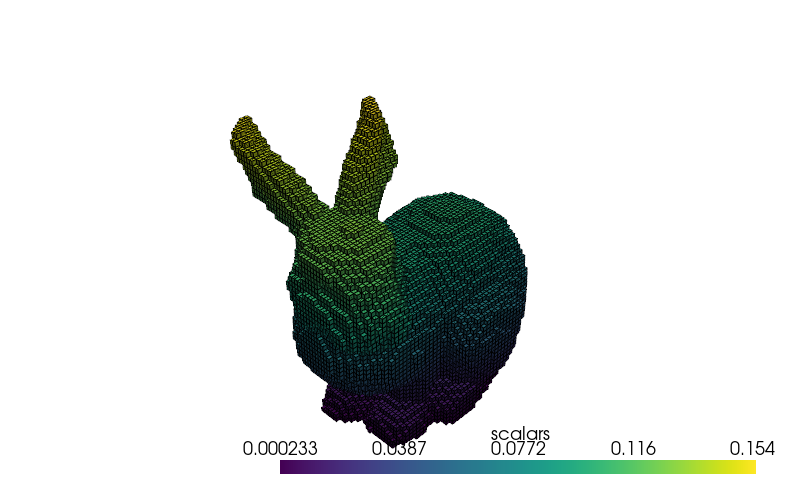

In [3]:
import pyvista as pv
from sigmaepsilon.mesh import PolyData, PointData, CartesianFrame
from sigmaepsilon.mesh.cells import H8

frame = CartesianFrame(dim=3)
voxel_pv = PolyData(
    PointData(coords=coords_H8, frame=frame),
    H8(topo=topo_H8[occupied], frames=frame),
).to_pv(multiblock=False, scalars=coords_H8[:, 2])[0]

plotter = pv.Plotter(notebook=True, window_size=(800, 500))
plotter.add_mesh(voxel_pv, cmap="viridis", show_edges=True)
plotter.camera_position = "iso"
plotter.show(jupyter_backend="static")

## Step 2: voxels back to mesh

Now the reverse. We pack the same occupancy values into a `pyvista.ImageData` -- VTK's structured-grid container -- using its `(i, j, k)` indices (its cell ordering has nothing to do with the order `grid()` returns topology in, which is exactly why we tracked `ix, iy, iz` above). Averaging the cell values onto the grid *points* turns the binary 0/1 occupancy into a continuous-looking density field between 0 and 1, which is what `contour(method="marching_cubes")` actually needs: a scalar sampled at points, not a flag per cell.

In [4]:
occupancy = np.zeros(shape, dtype=float)
occupancy[ix, iy, iz] = occupied.astype(float)

image = pv.ImageData(dimensions=np.array(shape) + 1, spacing=resolution, origin=shift)
image.cell_data["occupancy"] = occupancy.flatten(order="F")
image_points = image.cell_data_to_point_data()

reconstructed = image_points.contour(
    isosurfaces=[0.5], scalars="occupancy", method="marching_cubes"
)
reconstructed = reconstructed.compute_normals(auto_orient_normals=True)

print(f"{reconstructed.n_points} points, {reconstructed.n_cells} triangles")
print(f"watertight: {reconstructed.is_manifold}")

11060 points, 21766 triangles
watertight: False


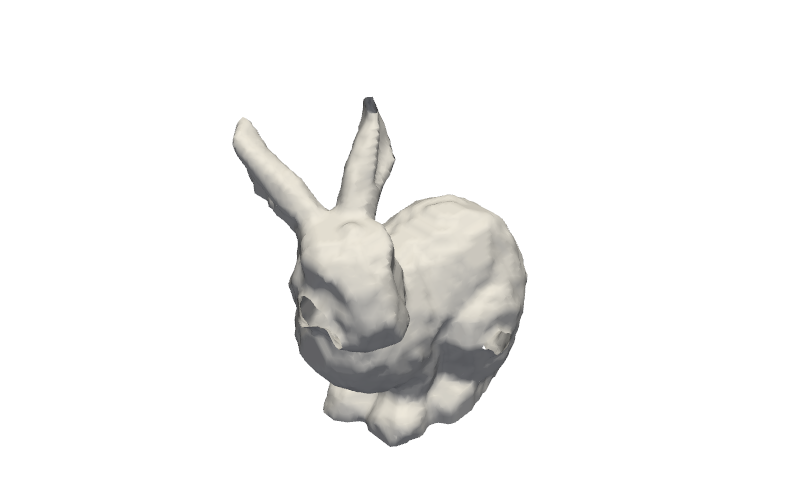

In [5]:
plotter = pv.Plotter(notebook=True, window_size=(800, 500))
plotter.add_mesh(reconstructed, color="white", smooth_shading=True)
plotter.camera_position = "iso"
plotter.show(jupyter_backend="static")

That `is_manifold` check is deliberate, not decorative. Classical marching cubes has well-known ambiguous cube configurations, and our occupancy field is coarse and quantized (averages of up to 8 neighbouring 0/1 cells), so a handful of tiny open edges around the ear tips are expected, not a bug in this library -- a genuine, frequently-cited limitation of the 1987 algorithm. It's also why production pipelines often reach for fixes like Marching Cubes 33 or Dual Contouring instead.

## The round trip, side by side

Three views of the same bunny: the original continuous surface, the blocky result of voxelizing it, and the smooth result of marching-cubing that voxelization back into a mesh.

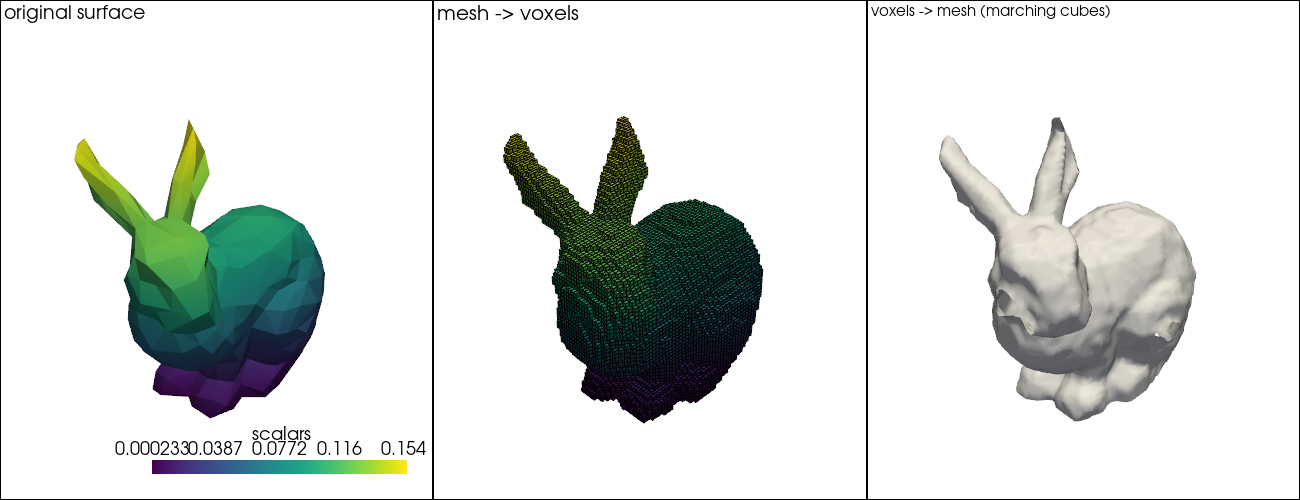

In [6]:
original_pv = mesh_surface.to_pv(multiblock=False, scalars=coords_T3[:, 2])[0]

plotter = pv.Plotter(notebook=True, window_size=(1300, 500), shape=(1, 3))
plotter.subplot(0, 0)
plotter.add_mesh(original_pv, cmap="viridis", show_edges=False)
plotter.add_text("original surface", font_size=10)
plotter.camera_position = "iso"
plotter.subplot(0, 1)
plotter.add_mesh(voxel_pv, cmap="viridis", show_edges=True)
plotter.add_text("mesh -> voxels", font_size=10)
plotter.camera_position = "iso"
plotter.subplot(0, 2)
plotter.add_mesh(reconstructed, color="white", smooth_shading=True)
plotter.add_text("voxels -> mesh (marching cubes)", font_size=10)
plotter.camera_position = "iso"
plotter.show(jupyter_backend="static")

## Quantifying the round trip

The blocky voxel grid and the marching-cubes surface come from the exact same occupancy data at the exact same resolution. Comparing their volume and area against the true, continuous bunny shows what interpolation buys you: the voxel grid systematically overestimates volume (every partially-covered cell is counted whole) while the interpolated surface gets much closer, simply because it's allowed to end a triangle partway through a cell instead of at its edge.

In [7]:
print(f"{'surface':<24}{'volume':>12}{'area':>12}")
print(f"{'original (true)':<24}{leaf_solid.volume():>12.6f}{leaf_surface.area():>12.6f}")
print(f"{'mesh -> voxels':<24}{voxel_pv.volume:>12.6f}{voxel_pv.extract_surface().area:>12.6f}")
print(f"{'voxels -> mesh (MC)':<24}{reconstructed.volume:>12.6f}{reconstructed.area:>12.6f}")

surface                       volume        area
original (true)             0.000746    0.058212


mesh -> voxels              0.000848    0.088239
voxels -> mesh (MC)         0.000830    0.056225


## Back to PolyData land

Everything past `voxelize_TET4_H8` in this notebook has been pure `pyvista`/VTK -- the marching cubes filter has nothing to do with this library. To actually use the reconstructed surface for anything downstream (further mesh operations, plotting through this library's API, saving with its I/O), it needs to come back in as a `PolyData`, the same way `import_pyvista.ipynb` brings in an arbitrary `pyvista` mesh.

<class 'sigmaepsilon.mesh.data.polydata.PolyData'>
11060 points, 21766 cells


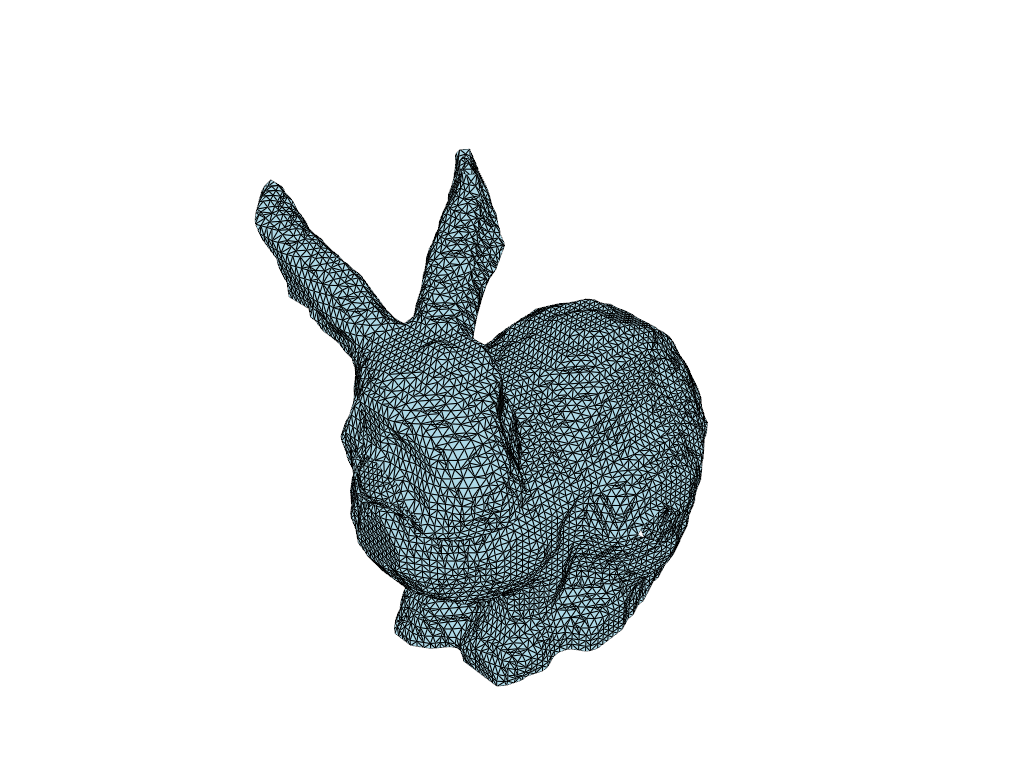

In [8]:
bunny_reconstructed = PolyData.from_pv(reconstructed)

print(type(bunny_reconstructed))
print(f"{bunny_reconstructed.number_of_points()} points, "
      f"{bunny_reconstructed.number_of_cells()} cells")

bunny_reconstructed.plot(notebook=True, jupyter_backend="static", theme="document")

The round trip is complete: a `PolyData` bunny was voxelized into hexahedra, those hexahedra were marched back into a triangulated surface by a completely different algorithm in a different library, and that surface is now a `PolyData` again -- ready for anything else in this gallery.

## Takeaway

`voxelize_T3_H8`/`voxelize_TET4_H8` and marching cubes sit on opposite ends of the same pipeline -- one turns continuous geometry into a discrete occupancy grid, the other turns a discrete grid back into continuous-looking geometry -- but neither one gets back exactly what the other started with. Voxelizing throws away curvature; marching cubes can only guess at it from how full the neighbouring cells were, and it inherits real, documented artifacts from doing so. Knowing which tool destroys information and which one approximates it is the whole point of putting them side by side.